# Лінійна фільтрація зображень

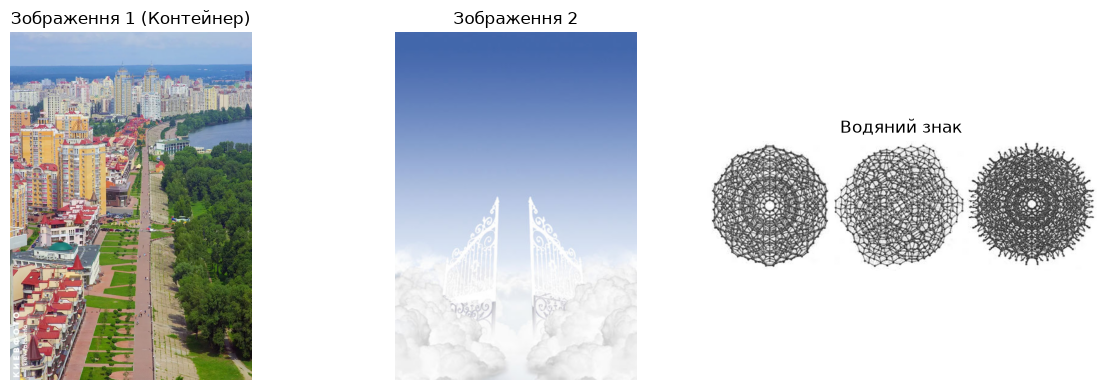

In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

path_img1 = '../data/obolon.png'          # Основне зображення-контейнер
path_img2 = '../data/paradise.jpg'          # Друге зображення для злиття
path_watermark = '../data/watermark.jpeg'  # Зображення водяного знаку

# 1. Завантаження основного зображення (з BGR у RGB)
img1 = cv2.imread(path_img1)
img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

# 2. Завантаження другого зображення та приведення до розмірів першого
img2 = cv2.imread(path_img2)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

# 3. Завантаження водяного знаку у градаціях сірого
watermark_img = cv2.imread(path_watermark, cv2.IMREAD_GRAYSCALE)

# Відображення завантажених зображень
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img1); axes[0].set_title("Зображення 1 (Контейнер)"); axes[0].axis('off')
axes[1].imshow(img2); axes[1].set_title("Зображення 2"); axes[1].axis('off')
axes[2].imshow(watermark_img, cmap='gray'); axes[2].set_title("Водяний знак"); axes[2].axis('off')
plt.tight_layout()
plt.show()

### a. Інвертування кольорової інтенсивності

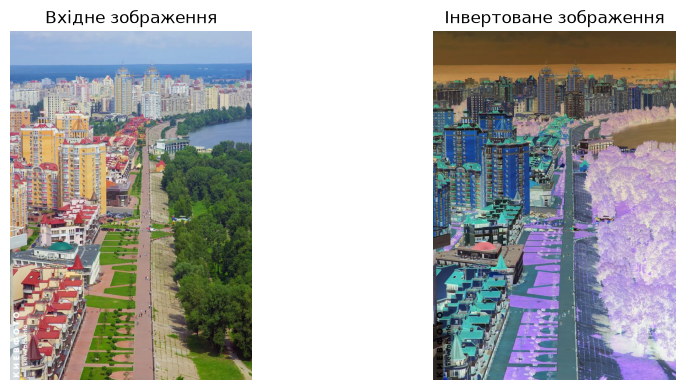

In [40]:
img_inverted = 255 - img1

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img1); axes[0].set_title("Вхідне зображення"); axes[0].axis('off')
axes[1].imshow(img_inverted); axes[1].set_title("Інвертоване зображення"); axes[1].axis('off')
plt.tight_layout()
plt.show()

### b. Зміна однієї кольорової компоненти

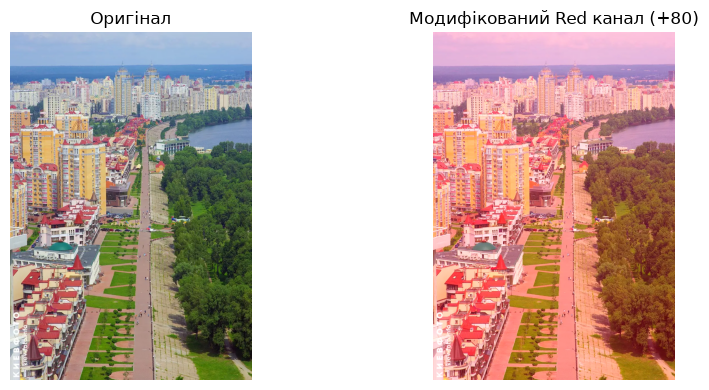

In [41]:
# Модифікація червоного каналу: додавання константи +80
img_red_mod = img1.astype(np.int16).copy()
img_red_mod[:, :, 0] += 80  # Канал Red
img_red_mod = np.clip(img_red_mod, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img1); axes[0].set_title("Оригінал"); axes[0].axis('off')
axes[1].imshow(img_red_mod); axes[1].set_title("Модифікований Red канал (+80)"); axes[1].axis('off')
plt.tight_layout()
plt.show()

### c. Розбивка зображення на Red, Green, Blue компоненти

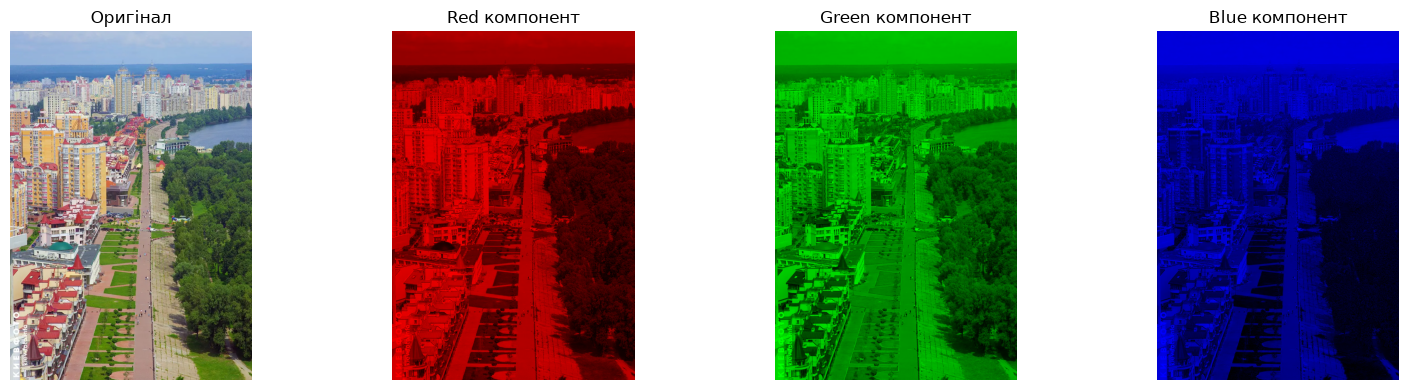

In [42]:
# Розкладання зображення на складові RGB канали
r_channel = img1.copy(); r_channel[:, :, 1] = 0; r_channel[:, :, 2] = 0
g_channel = img1.copy(); g_channel[:, :, 0] = 0; g_channel[:, :, 2] = 0
b_channel = img1.copy(); b_channel[:, :, 0] = 0; b_channel[:, :, 1] = 0

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img1); axes[0].set_title("Оригінал"); axes[0].axis('off')
axes[1].imshow(r_channel); axes[1].set_title("Red компонент"); axes[1].axis('off')
axes[2].imshow(g_channel); axes[2].set_title("Green компонент"); axes[2].axis('off')
axes[3].imshow(b_channel); axes[3].set_title("Blue компонент"); axes[3].axis('off')
plt.tight_layout()
plt.show()

### d. Злиття двох зображень із кроком зміни $\alpha$

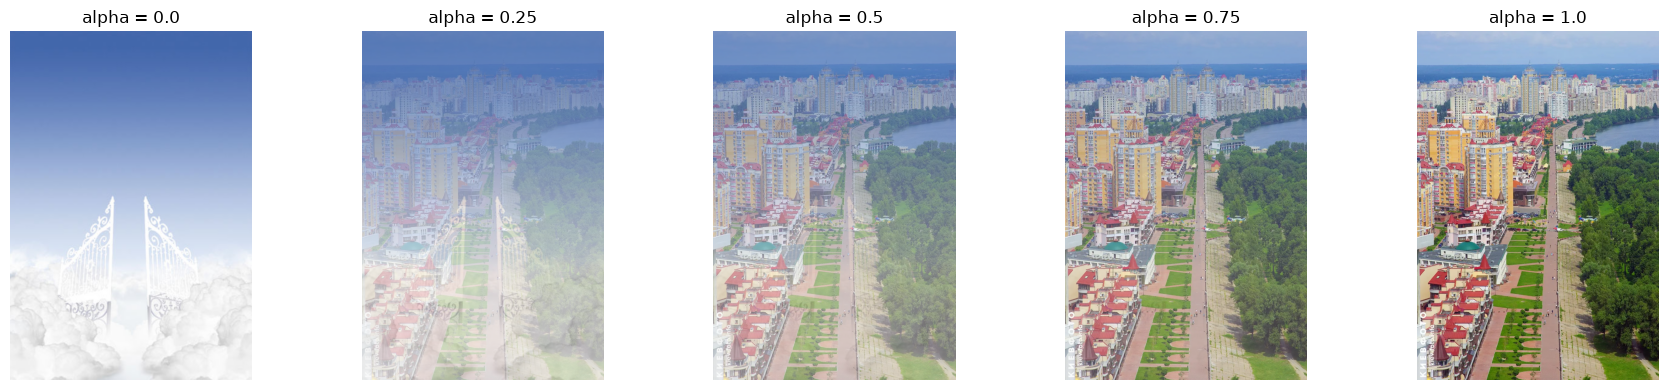

In [43]:
# Злиття зображень за формулою: Image_new = alpha * Image1 + (1 - alpha) * Image2
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(1, len(alphas), figsize=(18, 4))
for idx, alpha in enumerate(alphas):
    blended = alpha * img1.astype(np.float64) + (1.0 - alpha) * img2.astype(np.float64)
    blended = np.clip(blended, 0, 255).astype(np.uint8)
    axes[idx].imshow(blended)
    axes[idx].set_title(f"alpha = {alpha}")
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

### e. Матричні, медіанні та морфологічні фільтри

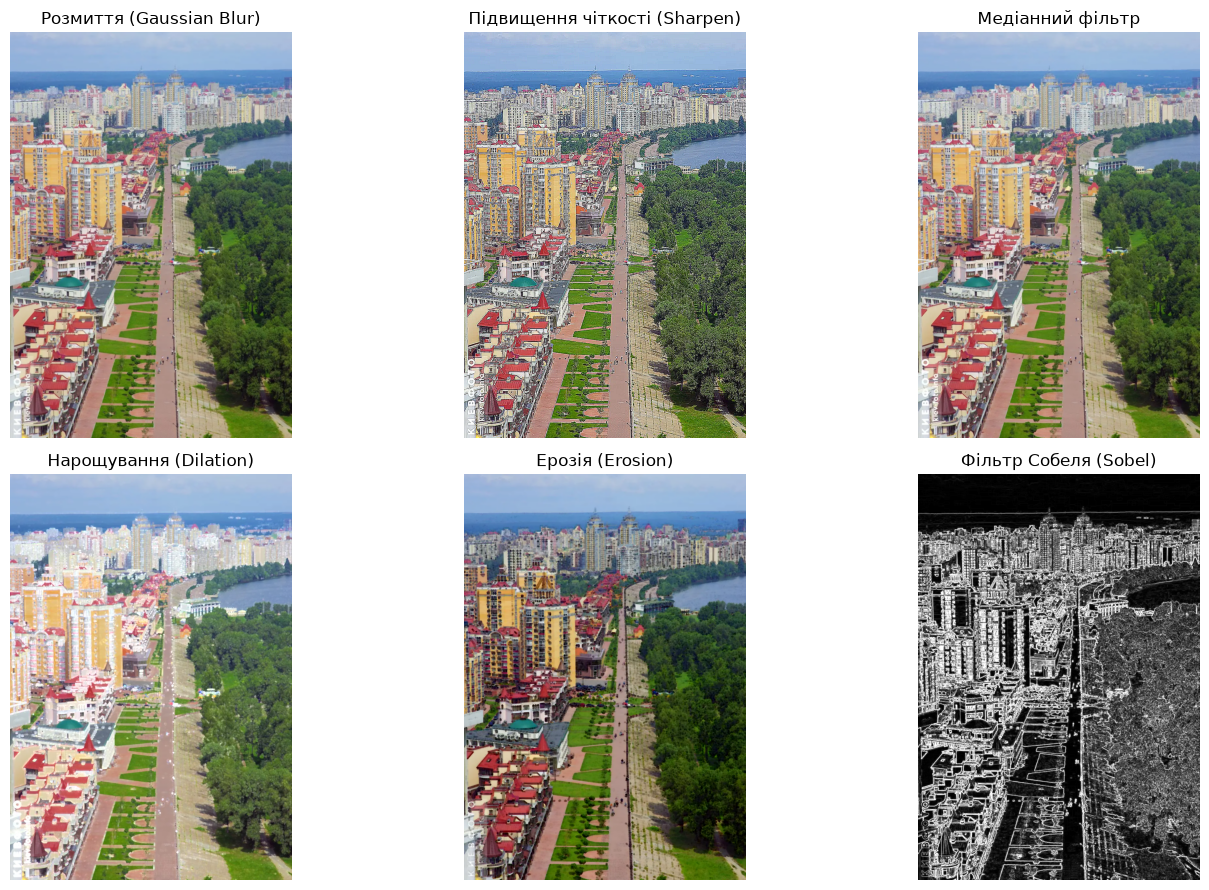

In [44]:
# 1. Загальна функція згортки з крайовим доповненням
def apply_convolution(image, kernel, div=1.0):
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w), (0, 0)), mode='edge')
    output = np.zeros_like(image, dtype=np.float64)
    for c in range(3):
        for i in range(image.shape[0]):
            for j in range(image.shape[1]):
                output[i, j, c] = np.sum(padded[i:i+kh, j:j+kw, c] * kernel) / div
    return np.clip(output, 0, 255).astype(np.uint8)

# 2. Фільтр розмиття Гауса 5x5
gaussian_kernel_5x5 = np.array([
    [0.000789, 0.006581, 0.013347, 0.006581, 0.000789],
    [0.006581, 0.054901, 0.111345, 0.054901, 0.006581],
    [0.013347, 0.111345, 0.225821, 0.111345, 0.013347],
    [0.006581, 0.054901, 0.111345, 0.054901, 0.006581],
    [0.000789, 0.006581, 0.013347, 0.006581, 0.000789]
], dtype=np.float64)

# 3. Фільтр поліпшення чіткості 3x3
sharpen_kernel = np.array([
    [-1, -1, -1],
    [-1,  9, -1],
    [-1, -1, -1]
], dtype=np.float64)

# 4. Медіанний фільтр 3x3
def apply_median(image, kernel_size=3):
    pad = kernel_size // 2
    padded = np.pad(image, ((pad, pad), (pad, pad), (0, 0)), mode='edge')
    output = np.zeros_like(image)
    for c in range(3):
        for i in range(image.shape[0]):
            for j in range(image.shape[1]):
                output[i, j, c] = np.median(padded[i:i+kernel_size, j:j+kernel_size, c])
    return output

# 5. Фільтри нарощування та ерозії 5x5 
binary_mask_5x5 = np.array([
    [0, 0, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [1, 1, 1, 1, 1],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 0, 0]
], dtype=bool)

def apply_morphology(image, mask, mode='dilation'):
    kh, kw = mask.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w), (0, 0)), mode='edge')
    output = np.zeros_like(image)
    for c in range(3):
        for i in range(image.shape[0]):
            for j in range(image.shape[1]):
                region = padded[i:i+kh, j:j+kw, c][mask]
                output[i, j, c] = np.max(region) if mode == 'dilation' else np.min(region)
    return output

# 6. Фільтр Собеля: G = sqrt(Gx^2 + Gy^2)
def apply_sobel(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY).astype(np.float64)
    pad = 1
    padded = np.pad(gray, ((pad, pad), (pad, pad)), mode='edge')
    
    Gy_kernel = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float64)
    Gx_kernel = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64)
    
    Gx = np.zeros_like(gray)
    Gy = np.zeros_like(gray)
    for i in range(gray.shape[0]):
        for j in range(gray.shape[1]):
            region = padded[i:i+3, j:j+3]
            Gx[i, j] = np.sum(region * Gx_kernel)
            Gy[i, j] = np.sum(region * Gy_kernel)
            
    G = np.sqrt(Gx**2 + Gy**2)
    return np.clip(G, 0, 255).astype(np.uint8)

# Застосування фільтрів
blur_res = apply_convolution(img1, gaussian_kernel_5x5, div=1.0)
sharp_res = apply_convolution(img1, sharpen_kernel, div=1.0)
median_res = apply_median(img1, kernel_size=3)
dilation_res = apply_morphology(img1, binary_mask_5x5, mode='dilation')
erosion_res = apply_morphology(img1, binary_mask_5x5, mode='erosion')
sobel_res = apply_sobel(img1)

# Відображення результатів
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes[0, 0].imshow(blur_res); axes[0, 0].set_title("Розмиття (Gaussian Blur)"); axes[0, 0].axis('off')
axes[0, 1].imshow(sharp_res); axes[0, 1].set_title("Підвищення чіткості (Sharpen)"); axes[0, 1].axis('off')
axes[0, 2].imshow(median_res); axes[0, 2].set_title("Медіанний фільтр"); axes[0, 2].axis('off')
axes[1, 0].imshow(dilation_res); axes[1, 0].set_title("Нарощування (Dilation)"); axes[1, 0].axis('off')
axes[1, 1].imshow(erosion_res); axes[1, 1].set_title("Ерозія (Erosion)"); axes[1, 1].axis('off')
axes[1, 2].imshow(sobel_res, cmap='gray'); axes[1, 2].set_title("Фільтр Собеля (Sobel)"); axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### f. Вбудовування бінарного водяного знаку у Blue-канал (LSB)

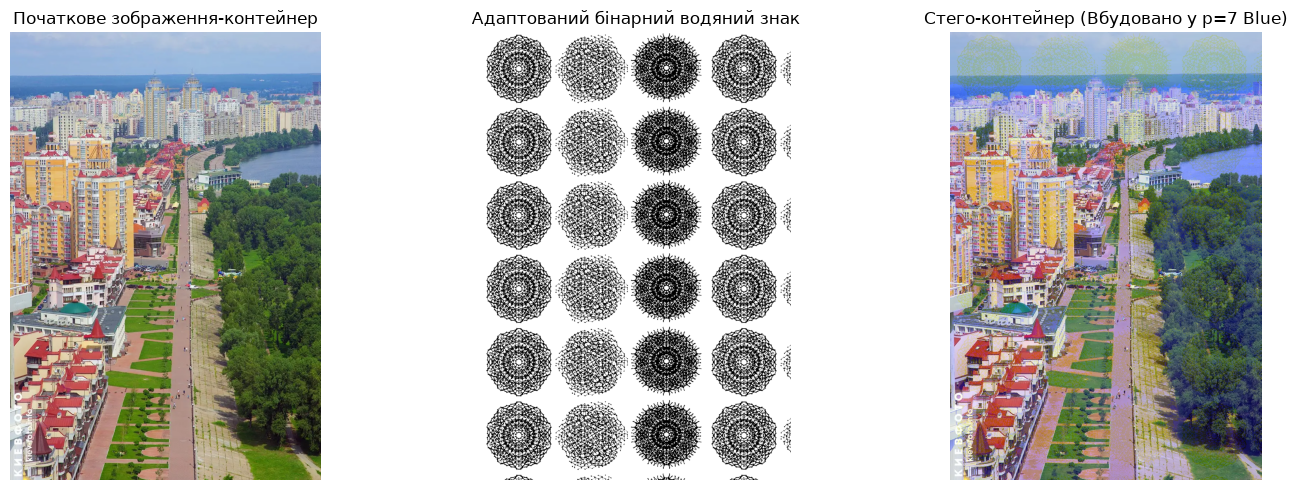

In [45]:
# Перетворення знаку до бінарного вигляду (0 або 1) та періодичне замощування/обрізання
def prepare_binary_watermark(watermark, container_shape):
    if watermark.ndim == 3:
        watermark = cv2.cvtColor(watermark, cv2.COLOR_RGB2GRAY)
    
    # Перетворення до чорно-білого бінарного масиву {0, 1}
    _, binary_wm = cv2.threshold(watermark, 128, 1, cv2.THRESH_BINARY)
    
    ch, cw = container_shape[:2]
    wh, ww = binary_wm.shape
    
    # Періодичне замощування, якщо контейнер більший, або обрізання, якщо менший
    rep_h = (ch // wh) + 1
    rep_w = (cw // ww) + 1
    tiled = np.tile(binary_wm, (rep_h, rep_w))
    return tiled[:ch, :cw]

def embed_lsb(container, watermark, bit_plane=2):
    """
    Вбудовування водяного знаку у p-ту бітову площину Blue-каналу
    C_p^W = W
    """
    stego = container.copy()
    blue = stego[:, :, 2]  # Вбудовуємо у Blue канал
    
    wm_binary = prepare_binary_watermark(watermark, container.shape)
    
    shift = bit_plane - 1
    mask = ~(1 << shift) & 0xFF  # Очищення p-го біта
    modified_blue = (blue & mask) | (wm_binary << shift)  # Встановлення біта знаку
    
    stego[:, :, 2] = modified_blue
    return stego, wm_binary

# Вбудовування у 2-у бітову площину (значення p від 1 до 8)
bit_plane_number = 7
stego_image, adapted_wm = embed_lsb(img1, watermark_img, bit_plane=bit_plane_number)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img1); axes[0].set_title("Початкове зображення-контейнер"); axes[0].axis('off')
axes[1].imshow(adapted_wm * 255, cmap='gray'); axes[1].set_title("Адаптований бінарний водяний знак"); axes[1].axis('off')
axes[2].imshow(stego_image); axes[2].set_title(f"Стего-контейнер (Вбудовано у p={bit_plane_number} Blue)"); axes[2].axis('off')
plt.tight_layout()
plt.show()

### g. Вилучення водяного знаку із заповненого контейнера

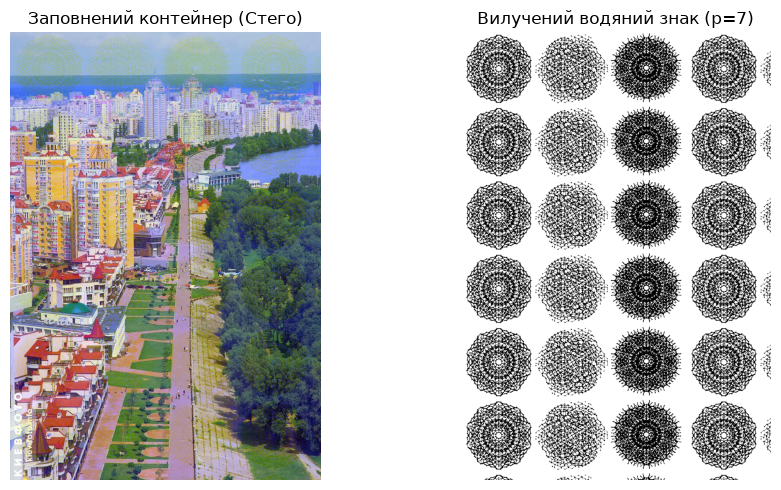

Збіг вилученого знаку з вбудованим: True


In [46]:
def extract_lsb(stego, bit_plane=2):
    """
    Вилучення водяного знаку з p-ї бітової площини Blue-каналу
    """
    blue = stego[:, :, 2]
    shift = bit_plane - 1
    
    extracted_bits = (blue >> shift) & 1  # Читання p-го біта
    return extracted_bits * 255

extracted_wm = extract_lsb(stego_image, bit_plane=bit_plane_number)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(stego_image); axes[0].set_title("Заповнений контейнер (Стего)"); axes[0].axis('off')
axes[1].imshow(extracted_wm, cmap='gray'); axes[1].set_title(f"Вилучений водяний знак (p={bit_plane_number})"); axes[1].axis('off')
plt.tight_layout()
plt.show()

# Перевірка відповідності вилученого знаку вбудованому
is_matching = np.array_equal(adapted_wm * 255, extracted_wm)
print(f"Збіг вилученого знаку з вбудованим: {is_matching}")